In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.stats import norm

In [2]:
DATA = Path("..") / "data"
prices = pd.read_csv(DATA / "prices.csv", index_col=0, parse_dates=True)
prices.tail()

,AMZN,GC=F,IWM,JNJ,JPM,NVDA,PG,SPY,VUSTX,XOM
Date,,,,,,,,,,
2026-10-12,259.529999,4190.600098,277.899994,263.730011,334.299988,226.320007,153.199997,778.099976,7.15,172.149994
2026-10-13,258.579987,4177.299805,276.700012,248.610001,331.429993,228.520004,153.039993,778.010010,7.18,174.080002
2026-10-14,254.080002,4107.899902,271.369995,253.910004,335.279999,221.300003,156.529999,769.599976,7.22,177.009995
2026-10-15,254.759995,4170.100098,275.079987,253.279999,335.529999,217.229996,157.080002,771.789978,7.31,174.679993
2026-10-16,249.509995,4191.500000,270.250000,255.520004,337.984985,214.619995,159.070007,762.489990,NaN,178.580002


In [3]:
"""
1    Monte Carlo i podstawy    Jak szybko zbiega estymacja i jak ją przyspieszyć?    Symulacja zmiennych losowych, LLN/CLT na wykresach, estymacja prawdopodobieństw ogonowych i straty portfela, zmienne antytetyczne i kontrolne. Tematycznie zgrany z Blitzsteinem.
2    Algebra liniowa w finansach    Czy lepsza estymacja kowariancji poprawia prognozę ryzyka poza próbą?    Rozkład własny i PCA stóp zwrotu, Cholesky do symulacji skorelowanych aktywów, shrinkage (Ledoit–Wolf), odszumianie macierzy (Marchenko–Pastur), porównanie portfeli minimalnej wariancji poza próbą.
3    Szeregi czasowe: pairs trading    Czy kointegracja daje stabilny sygnał po kosztach?    Testy stacjonarności (ADF, KPSS), Engle–Granger, dobór pary, z-score spreadu, backtest walk-forward z kosztami transakcyjnymi. Dane np. S&P 500 i WIG.
4    Ryzyko ogonowe (EVT)    Czy rozkład Pareto dla ogona lepiej opisuje skrajne straty niż normalny?    Metoda POT i rozkład GPD, VaR/ES z EVT, porównanie z metodami historycznymi. Jeśli Twoja praca już obejmuje EVT, zamień na moduł o estymatorach zmienności (range-based, np. Parkinson)
"""

'\n1    Monte Carlo i podstawy    Jak szybko zbiega estymacja i jak ją przyspieszyć?    Symulacja zmiennych losowych, LLN/CLT na wykresach, estymacja prawdopodobieństw ogonowych i straty portfela, zmienne antytetyczne i kontrolne. Tematycznie zgrany z Blitzsteinem.\n2    Algebra liniowa w finansach    Czy lepsza estymacja kowariancji poprawia prognozę ryzyka poza próbą?    Rozkład własny i PCA stóp zwrotu, Cholesky do symulacji skorelowanych aktywów, shrinkage (Ledoit–Wolf), odszumianie macierzy (Marchenko–Pastur), porównanie portfeli minimalnej wariancji poza próbą.\n3    Szeregi czasowe: pairs trading    Czy kointegracja daje stabilny sygnał po kosztach?    Testy stacjonarności (ADF, KPSS), Engle–Granger, dobór pary, z-score spreadu, backtest walk-forward z kosztami transakcyjnymi. Dane np. S&P 500 i WIG.\n4    Ryzyko ogonowe (EVT)    Czy rozkład Pareto dla ogona lepiej opisuje skrajne straty niż normalny?    Metoda POT i rozkład GPD, VaR/ES z EVT, porównanie z metodami historycznymi

In [4]:
data_returns = np.log(prices / prices.shift(1)).dropna()
data_returns.head()

,AMZN,GC=F,IWM,JNJ,JPM,NVDA,PG,SPY,VUSTX,XOM
Date,,,,,,,,,,
2000-09-05,0.096131,-0.004342,-0.006945,0.006725,0.014326,0.001572,0.018164,-0.008024,-0.000954,0.010551
2000-09-06,0.004096,-0.005818,-0.004365,0.000000,-0.019890,-0.071576,0.014888,-0.011427,-0.004777,-0.004508
2000-09-07,-0.053159,-0.000730,0.014764,0.002009,0.022076,0.052558,-0.012890,0.008530,-0.000958,0.008995
2000-09-08,-0.013015,-0.002558,-0.017392,0.010976,0.009777,-0.061025,0.012890,-0.006860,0.001915,-0.002990
2000-09-11,-0.013187,-0.000732,0.001169,0.005772,-0.005420,-0.041673,-0.011892,-0.001461,-0.003836,0.017621


In [5]:
data_mean = data_returns.mean()
data_mean

AMZN     0.000676
GC=F     0.000391
IWM      0.000296
JNJ      0.000378
JPM      0.000378
NVDA     0.000953
PG       0.000363
SPY      0.000322
VUSTX    0.000161
XOM      0.000359
dtype: float64

In [6]:
data_std = data_returns.std()
data_std

AMZN     0.028776
GC=F     0.011281
IWM      0.015030
JNJ      0.011689
JPM      0.022848
NVDA     0.035062
PG       0.011913
SPY      0.012032
VUSTX    0.007818
XOM      0.016417
dtype: float64

In [7]:
# EQUAL-WEIGHT PORTFOLIO

n = len(prices.columns)
weights = np.asarray([1 / n] * n)

ew_portfolio_returns = data_returns.dot(weights)
ew_portfolio_mean = ew_portfolio_returns.mean()
ew_portfolio_std = ew_portfolio_returns.std()

print(f"Equal-Weight Portfolio mean : {float(ew_portfolio_mean):.5f}")
print(f"Equal-Weight Portfolio std : {float(ew_portfolio_std):.5f}")

Equal-Weight Portfolio mean : 0.00043
Equal-Weight Portfolio std : 0.01054


In [8]:
# Normal Distribution VaR
normal_var = norm.ppf(0.01, loc=ew_portfolio_mean, scale=ew_portfolio_std)
print(f"normal VaR: {float(normal_var)}")

# Monte Carlo VaR
size = 10000
rng = np.random.default_rng(42)
mc_returns = rng.normal(loc=ew_portfolio_mean, scale=ew_portfolio_std, size=size)

monte_carlo_var = np.percentile(mc_returns, 1)
print(f"monte carlo VaR: {float(monte_carlo_var)}")

# Bootstrap VaR
size = 10000
boot_returns = rng.choice(ew_portfolio_returns, size=size, replace=True)
bootstrap_var = np.percentile(boot_returns, 1)
print(f"bootstrap VaR: {float(bootstrap_var)}")

# Historical VaR
historical_var = np.percentile(ew_portfolio_returns, 1)
print(f"historical VaR {float(historical_var)}")

normal VaR: -0.02408421479579366
monte carlo VaR: -0.024584317425420835
bootstrap VaR: -0.029708076491886143
historical VaR -0.029619421546738463


In [8]:
"""
According to LLN (Law of Large Numbers) and CLT (Central Limit Theorem), the standard estimation error
is reduced in reverse proportion to the number of samples- 1 / sqrt(n).
To show this, i will use Monte Carlo simulation to visualize the estimation error.
"""

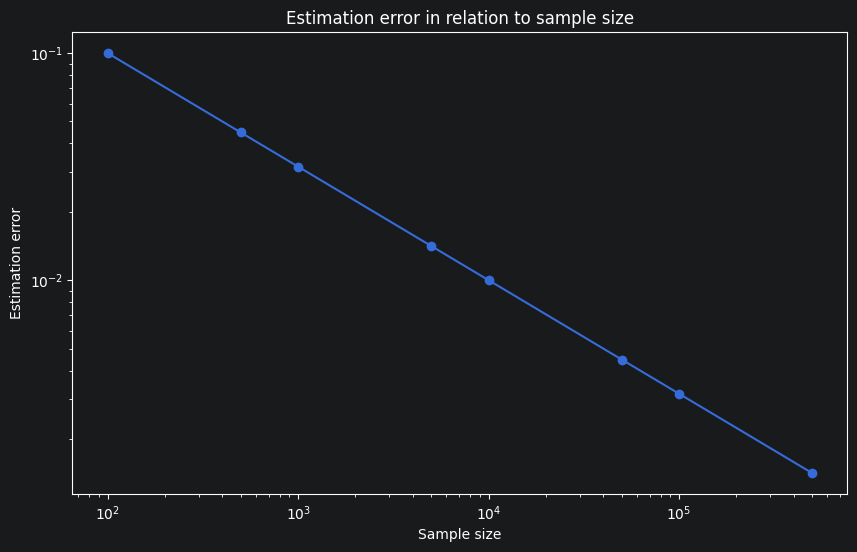

In [11]:
sample_sizes = [100, 500, 1000, 5000, 10000, 50000, 100000, 500000]
estimation_errors = []

for sample in sample_sizes:
    estimation_errors.append(1 / np.sqrt(sample))

fig = plt.figure(figsize=(10, 6))
plt.title("Estimation error in relation to sample size")
plt.loglog(sample_sizes, estimation_errors, marker="o")
plt.xlabel("Sample size")
plt.ylabel("Estimation error")
plt.show()

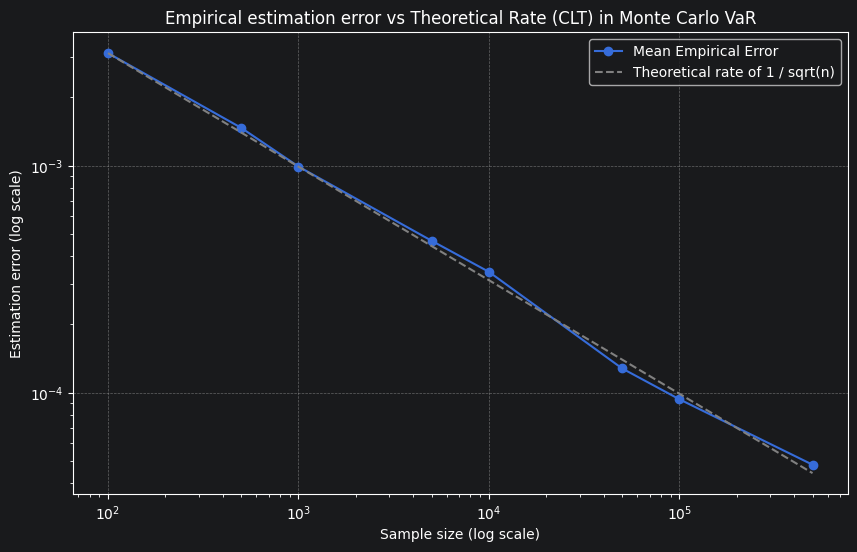

In [18]:
sample_sizes = [100, 500, 1000, 5000, 10000, 50000, 100000, 500000]
num_simulations = 50
mean_empirical_errors = []

true_var = norm.ppf(0.01, loc=ew_portfolio_mean, scale=ew_portfolio_std)

for sample in sample_sizes:
    sim_matrix = rng.normal(loc=ew_portfolio_mean, scale=ew_portfolio_std, size=(num_simulations, sample))
    mc_var = np.percentile(sim_matrix, 1, axis=1)
    empirical_error = np.mean(np.abs(mc_var - true_var))
    mean_empirical_errors.append(empirical_error)

fig = plt.figure(figsize=(10, 6))
plt.title("Empirical estimation error vs Theoretical Rate (CLT) in Monte Carlo VaR")
plt.loglog(sample_sizes, mean_empirical_errors, marker="o", label="Mean Empirical Error")

ref_line = [mean_empirical_errors[0] * np.sqrt(sample_sizes[0]) / np.sqrt(sample) for sample in sample_sizes]
plt.loglog(sample_sizes, ref_line, linestyle="--", color="gray",  label="Theoretical rate of 1 / sqrt(n)")

plt.xlabel("Sample size (log scale)")
plt.ylabel("Estimation error (log scale)")
plt.legend()
plt.grid(True, ls="--")

plt.show()